In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [3]:
df = pd.read_csv("job_hunt_tracker_100000.csv")

In [4]:
df.head()

,Application_ID,Candidate_ID,Company,Job_Role,Location,Work_Mode,Applied_Date,Job_Source,Experience_Years,Expected_Salary_LPA,Status,Follow_Up_Date,Interview_Date,HR_Contact,Notes
0,100001,4341,Paytm,Data Science Intern,Pune,On-site,2025-04-13,Apna,2,5.4,Shortlisted,2025-04-20,NaN,hr0@talent-example.com,Follow-up required
1,100002,3512,Zomato,BI Analyst,Jaipur,On-site,2026-03-12,Indeed,1,17.6,No Response,2026-03-19,NaN,hr1@careers-example.com,Follow-up required
2,100003,2133,KPMG,SQL Developer,Chennai,On-site,2025-09-28,LinkedIn,2,9.3,Applied,2025-10-08,NaN,hr2@careers-example.com,Follow-up required
3,100004,3024,IBM,Reporting Analyst,Lucknow,On-site,2025-04-17,Internshala,4,16.0,Interviewed,2025-04-27,2025-05-15,hr3@talent-example.com,Not specified
4,100005,1564,PhonePe,Power BI Developer,Gurgaon,Remote,2025-03-13,Indeed,0,7.2,Applied,2025-03-27,NaN,hr4@jobs-example.com,HR discussion pending


In [5]:
df.info

<bound method DataFrame.info of        Application_ID  Candidate_ID    Company             Job_Role  \
0              100001          4341      Paytm  Data Science Intern   
1              100002          3512     Zomato           BI Analyst   
2              100003          2133       KPMG        SQL Developer   
3              100004          3024        IBM    Reporting Analyst   
4              100005          1564    PhonePe   Power BI Developer   
...               ...           ...        ...                  ...   
99995          199996          2631    Mphasis    Backend Developer   
99996          199997          3018     Swiggy  Data Science Intern   
99997          199998          5427      Wipro     Business Analyst   
99998          199999          1311   Flipkart    Reporting Analyst   
99999          200000          5787  Microsoft    Backend Developer   

        Location Work_Mode Applied_Date        Job_Source  Experience_Years  \
0           Pune   On-site   2025-04

In [6]:
df.columns

Index(['Application_ID', 'Candidate_ID', 'Company', 'Job_Role', 'Location',
       'Work_Mode', 'Applied_Date', 'Job_Source', 'Experience_Years',
       'Expected_Salary_LPA', 'Status', 'Follow_Up_Date', 'Interview_Date',
       'HR_Contact', 'Notes'],
      dtype='str')

In [7]:
df.columns.str.lower()

Index(['application_id', 'candidate_id', 'company', 'job_role', 'location',
       'work_mode', 'applied_date', 'job_source', 'experience_years',
       'expected_salary_lpa', 'status', 'follow_up_date', 'interview_date',
       'hr_contact', 'notes'],
      dtype='str')

In [23]:
# Categorical columns analysis
# Duplicate records
# Missing values
# Date range

In [24]:
stat = ["Status","Job_Source","Work_Mode"]
for i in stat:
    print(i, df[i].value_counts(dropna= False).head(10).to_dict())
print("duplicates",df['Application_ID'].duplicated().sum())
print("missing", df.isnull().sum().to_dict())
print("data range", df['Applied_Date'].min(), df['Applied_Date'].max())

Status {'Applied': 30027, 'Rejected': 17821, 'Shortlisted': 11879, 'Interviewed': 10167, 'Interview Scheduled': 10084, 'No Response': 10048, 'Offer Received': 6004, 'Withdrawn': 3970}
Job_Source {'Indeed': 12664, ' company website': 12599, 'Foundit': 12495, 'Naukri': 12484, 'Referral': 12468, 'Internshala': 12455, 'Apna': 12435, 'LinkedIn': 12400}
Work_Mode {'On-site': 55014, 'Hybrid': 25134, 'Remote': 19852}
duplicates 0
missing {'Application_ID': 0, 'Candidate_ID': 0, 'Company': 0, 'Job_Role': 0, 'Location': 0, 'Work_Mode': 0, 'Applied_Date': 0, 'Job_Source': 0, 'Experience_Years': 0, 'Expected_Salary_LPA': 0, 'Status': 0, 'Follow_Up_Date': 0, 'Interview_Date': 73745, 'HR_Contact': 0, 'Notes': 0}
data range 2025-01-01 2026-11-03


# FEATURE ENGINEERING

In [28]:
response_status = [
    "Shortlisted",
    "Interview Scheduled",
    "Interviewed",
    "Offer Received",
    "Rejected"
]

interview_status = [
    "Interview Scheduled",
    "Interviewed",
    "Offer Received"
]

df["Responded"] = df["Status"].isin(
    response_status
)

df["Interview_Reached"] = df["Status"].isin(
    interview_status
)

df["Offer"] = df["Status"].eq(
    "Offer Received"
)


#### day to interview 

In [30]:
df['Days_To_Interview'] = (df['Interview_Date']-df['Applied_Date']).dt.days


##### application age

In [ ]:
today = 

Dataset Shape: (100000, 15)
   Application_ID  Candidate_ID  Company             Job_Role Location  \
0          100001          4341    Paytm  Data Science Intern     Pune   
1          100002          3512   Zomato           BI Analyst   Jaipur   
2          100003          2133     KPMG        SQL Developer  Chennai   
3          100004          3024      IBM    Reporting Analyst  Lucknow   
4          100005          1564  PhonePe   Power BI Developer  Gurgaon   

  Work_Mode Applied_Date   Job_Source  Experience_Years  Expected_Salary_LPA  \
0   On-site   2025-04-13         Apna                 2                  5.4   
1   On-site   2026-03-12       Indeed                 1                 17.6   
2   On-site   2025-09-28     LinkedIn                 2                  9.3   
3   On-site   2025-04-17  Internshala                 4                 16.0   
4    Remote   2025-03-13       Indeed                 0                  7.2   

        Status Follow_Up_Date Interview_Date  

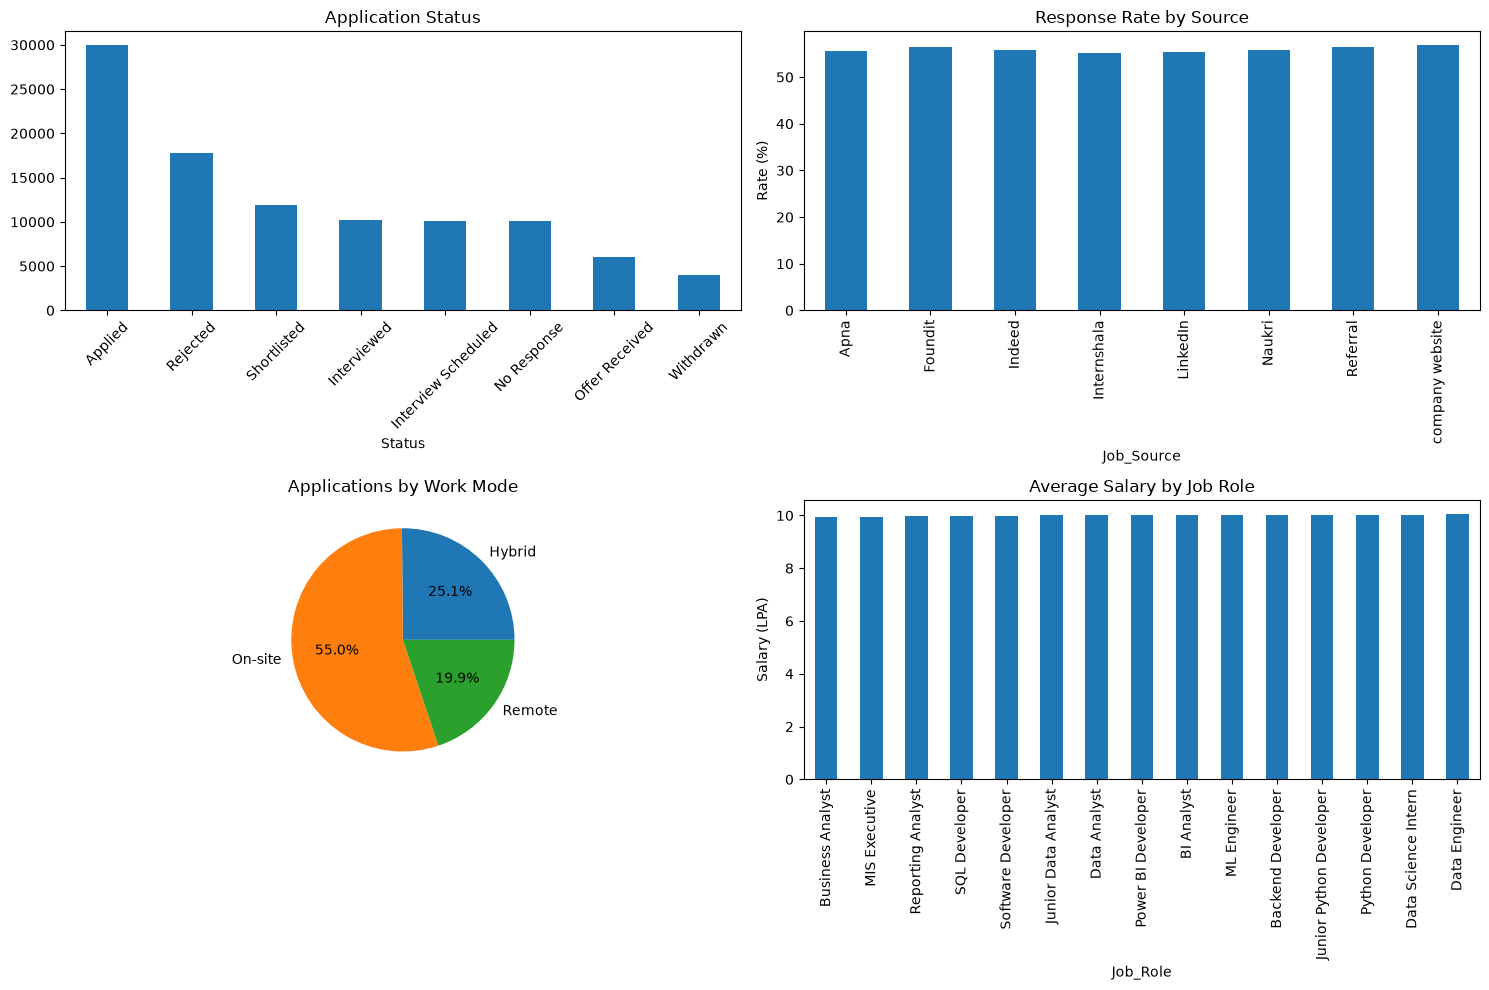

In [26]:

# Days to interview
df["Days_To_Interview"] = (
    df["Interview_Date"] - df["Applied_Date"]
).dt.days

# Application age
today = pd.Timestamp.today().normalize()

df["Application_Age"] = (
    today - df["Applied_Date"]
).dt.days

# ==================================
# 4. KPI ANALYSIS
# ==================================

total = len(df)
responses = df["Responded"].sum()
interviews = df["Interview_Reached"].sum()
offers = df["Offer"].sum()

print("\n========== JOB HUNT KPIs ==========")

print("Total Applications:", total)

print("Response Rate:",
      round(responses / total * 100, 2), "%")

print("Interview Rate:",
      round(interviews / total * 100, 2), "%")

print("Offer Rate:",
      round(offers / total * 100, 2), "%")

# ==================================
# 5. STATUS ANALYSIS
# ==================================

status_analysis = (
    df["Status"]
    .value_counts()
    .reset_index()
)

status_analysis.columns = [
    "Status", "Count"
]

print("\nSTATUS ANALYSIS")
print(status_analysis)

# ==================================
# 6. SOURCE ANALYSIS
# ==================================

source_analysis = df.groupby(
    "Job_Source"
).agg(
    Applications=("Application_ID", "count"),
    Responses=("Responded", "sum"),
    Interviews=("Interview_Reached", "sum"),
    Offers=("Offer", "sum")
)

source_analysis["Response_Rate"] = (
    source_analysis["Responses"] /
    source_analysis["Applications"] * 100
)

source_analysis["Interview_Rate"] = (
    source_analysis["Interviews"] /
    source_analysis["Applications"] * 100
)

source_analysis["Offer_Rate"] = (
    source_analysis["Offers"] /
    source_analysis["Applications"] * 100
)

print("\nSOURCE ANALYSIS")
print(source_analysis.round(2))

# ==================================
# 7. COMPANY ANALYSIS
# ==================================

company_analysis = df.groupby(
    "Company"
).agg(
    Applications=("Application_ID", "count"),
    Interviews=("Interview_Reached", "sum"),
    Offers=("Offer", "sum")
)

company_analysis = company_analysis.sort_values(
    "Applications", ascending=False
)

print("\nTOP 10 COMPANIES")
print(company_analysis.head(10))

# ==================================
# 8. WORK MODE ANALYSIS
# ==================================

work_analysis = df.groupby(
    "Work_Mode"
).agg(
    Applications=("Application_ID", "count"),
    Interviews=("Interview_Reached", "sum"),
    Offers=("Offer", "sum")
)

work_analysis["Interview_Rate"] = (
    work_analysis["Interviews"] /
    work_analysis["Applications"] * 100
)

print("\nWORK MODE ANALYSIS")
print(work_analysis.round(2))

# ==================================
# 9. SALARY ANALYSIS
# ==================================

salary_analysis = df.groupby(
    "Job_Role"
)["Expected_Salary_LPA"].agg(
    ["mean", "min", "max"]
)

print("\nSALARY ANALYSIS")
print(salary_analysis.round(2))

# ==================================
# 10. GHOST RATE
# ==================================

ghost_df = df[
    (df["Application_Age"] > 21) &
    (df["Status"].isin(["Applied", "No Response"]))
]

eligible_df = df[
    df["Application_Age"] > 21
]

ghost_rate = (
    len(ghost_df) / len(eligible_df) * 100
    if len(eligible_df) else 0
)

print("\nGHOST RATE:", round(ghost_rate, 2), "%")

# ==================================
# 11. WILSON CONFIDENCE INTERVAL
# ==================================

def wilson(k, n, z=1.96):

    if n == 0:
        return np.nan, np.nan

    p = k / n

    centre = (
        p + z**2 / (2*n)
    ) / (1 + z**2/n)

    half = (
        z * np.sqrt(
            p*(1-p)/n + z**2/(4*n**2)
        ) / (1 + z**2/n)
    )

    return centre-half, centre+half


print("\nSOURCE CONFIDENCE INTERVAL")

for source, row in source_analysis.iterrows():

    low, high = wilson(
        row["Responses"],
        row["Applications"]
    )

    print(
        source,
        "95% CI:",
        round(low*100, 2),
        "-",
        round(high*100, 2), "%"
    )

# ==================================
# 12. SQLITE DATABASE
# ==================================

conn = sqlite3.connect("job_hunt.db")

df.to_sql(
    "applications",
    conn,
    if_exists="replace",
    index=False
)

print("\nSQLite Database Created!")

conn.close()

# ==================================
# 13. EXPORT ANALYSIS
# ==================================

status_analysis.to_csv(
    "status_analysis.csv", index=False
)

source_analysis.to_csv(
    "source_analysis.csv"
)

company_analysis.to_csv(
    "company_analysis.csv"
)

print("\nAnalysis CSV Files Exported!")

# ==================================
# 14. DASHBOARD
# ==================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: Status distribution
status_analysis.plot(
    x="Status",
    y="Count",
    kind="bar",
    ax=axes[0, 0],
    legend=False
)

axes[0, 0].set_title("Application Status")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: Response rate by source
source_analysis["Response_Rate"].plot(
    kind="bar",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Response Rate by Source")
axes[0, 1].set_ylabel("Rate (%)")

# Chart 3: Work mode
work_analysis["Applications"].plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Applications by Work Mode")
axes[1, 0].set_ylabel("")

# Chart 4: Salary by role
salary_analysis["mean"].sort_values().plot(
    kind="bar",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Average Salary by Job Role")
axes[1, 1].set_ylabel("Salary (LPA)")

plt.tight_layout()

plt.savefig("job_hunt_dashboard.png")

plt.show()
